<a href="https://colab.research.google.com/github/Adithya759/Adithya/blob/main/Retest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Task 1


In [4]:
import pandas as pd
df = pd.read_csv('/content/patients.csv')
df['arrival_date'] = pd.to_datetime(df['arrival_date'])
df['Week'] = df['arrival_date'].dt.isocalendar().week
df['Week'] = 'Week_' + df['Week'].astype(str)
print(df[['arrival_date', 'Week']].head())


  arrival_date     Week
0   2025-03-16  Week_11
1   2025-12-13  Week_50
2   2025-06-29  Week_26
3   2025-10-12  Week_41
4   2025-02-18   Week_8


Analytical Questiion:
patients.csv: Each row represents a unique patient visit, with attributes like age, service type, satisfaction score, and admission/discharge dates.

services_weekly.csv: The granularity is weekly service-level operations. Each row summarizes operational metrics (e.g., staffing, bed availability, throughput) for a specific service (e.g., ICU, surgery) in a given week.

These two datasets operate at different levels of granularity. To build a predictive model (e.g., forecasting patient satisfaction or resource needs)

In [5]:
services_weekly = pd.read_csv('/content/services_weekly.csv')
print(services_weekly.head())


   week  month           service  available_beds  patients_request  \
0     1      1         emergency              32                76   
1     1      1           surgery              45               130   
2     1      1  general_medicine              37               201   
3     1      1               ICU              22                31   
4     2      1         emergency              28               169   

   patients_admitted  patients_refused  patient_satisfaction  staff_morale  \
0                 32                44                    67            70   
1                 45                85                    83            78   
2                 37               164                    97            43   
3                 22                 9                    84            91   
4                 28               141                    75            64   

  event  
0  none  
1   flu  
2   flu  
3   flu  
4  none  


In [6]:
patients = pd.read_csv('patients.csv')
patients['arrival_date'] = pd.to_datetime(patients['arrival_date'])
patients['Week'] = patients['arrival_date'].dt.isocalendar().week
services_weekly = pd.read_csv('services_weekly.csv')
print(patients[['patient_id', 'arrival_date', 'Week', 'service']].head())
print(services_weekly.head())


     patient_id arrival_date  Week           service
0  PAT-09484753   2025-03-16    11           surgery
1  PAT-f0644084   2025-12-13    50           surgery
2  PAT-ac6162e4   2025-06-29    26  general_medicine
3  PAT-3dda2bb5   2025-10-12    41         emergency
4  PAT-08591375   2025-02-18     8               ICU
   week  month           service  available_beds  patients_request  \
0     1      1         emergency              32                76   
1     1      1           surgery              45               130   
2     1      1  general_medicine              37               201   
3     1      1               ICU              22                31   
4     2      1         emergency              28               169   

   patients_admitted  patients_refused  patient_satisfaction  staff_morale  \
0                 32                44                    67            70   
1                 45                85                    83            78   
2                 37       

#Task 2

In [10]:

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
patients['arrival_date'] = pd.to_datetime(patients['arrival_date'])
patients['departure_date'] = pd.to_datetime(patients['departure_date'])
patients['Week'] = patients['arrival_date'].dt.isocalendar().week
patients['LengthOfStay'] = (patients['departure_date'] - patients['arrival_date']).dt.days
services = pd.read_csv('services_weekly.csv')
merged = pd.merge(
    patients,
    services,
    left_on=['Week', 'service'],
    right_on=['week', 'service'],
    how='inner'
)
y = merged['satisfaction']
X = merged[['LengthOfStay', 'service', 'available_beds', 'patients_request', 'staff_morale']]
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(), ['service']),
        ('num', StandardScaler(), ['LengthOfStay', 'available_beds', 'patients_request', 'staff_morale'])
    ]
)
pipeline = Pipeline(steps=[('preprocessor', preprocessor)])
X_preprocessed = pipeline.fit_transform(X)

Analytical Questiion:An inner merge ensures that only patient records with matching operational data (from services_weekly.csv) are retained. This is crucial for modeling because we need both patient-level outcomes and service-level features to build meaningful predictions. Without operational context (e.g., staffing, bed availability), the model would lack key explanatory variables.

In [9]:

X_preprocessed = preprocessor.fit_transform(X)

print("Preprocessed feature matrix shape:", X_preprocessed.shape)
print("Target vector shape:", y.shape)


Preprocessed feature matrix shape: (1000, 8)
Target vector shape: (1000,)


#Task 3

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
X_train, X_test, y_train, y_test = train_test_split(X_preprocessed, y, test_size=0.2, random_state=42)
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
rf_model = RandomForestRegressor(random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print(" Linear Regression:")
print("  RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_linear)))
print("  R² Score:", r2_score(y_test, y_pred_linear))

print("\n Random Forest:")
print("  RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("  R² Score:", r2_score(y_test, y_pred_rf))

 Linear Regression:
  RMSE: 11.950600873108629
  R² Score: -0.006620931637114635

 Random Forest:
  RMSE: 13.56210545456451
  R² Score: -0.2964050280046411


Analytical Qn :A key advantage of using a complex, non-linear model like Random Forest over a simple Linear Regression is its ability to capture non-linear relationships and interactions between features.

The feature StaffAssigned (staff_morale) is an example. Its effect on patient satisfaction may not be linear — increasing staff morale from 40 to 60 might have minimal impact, but boosting it from 80 to 90 could significantly improve satisfaction. Additionally, the impact of staff morale might vary depending on the service type (e.g., ICU vs. general medicine), or interact with other features like LengthOfStay.




#Task 4


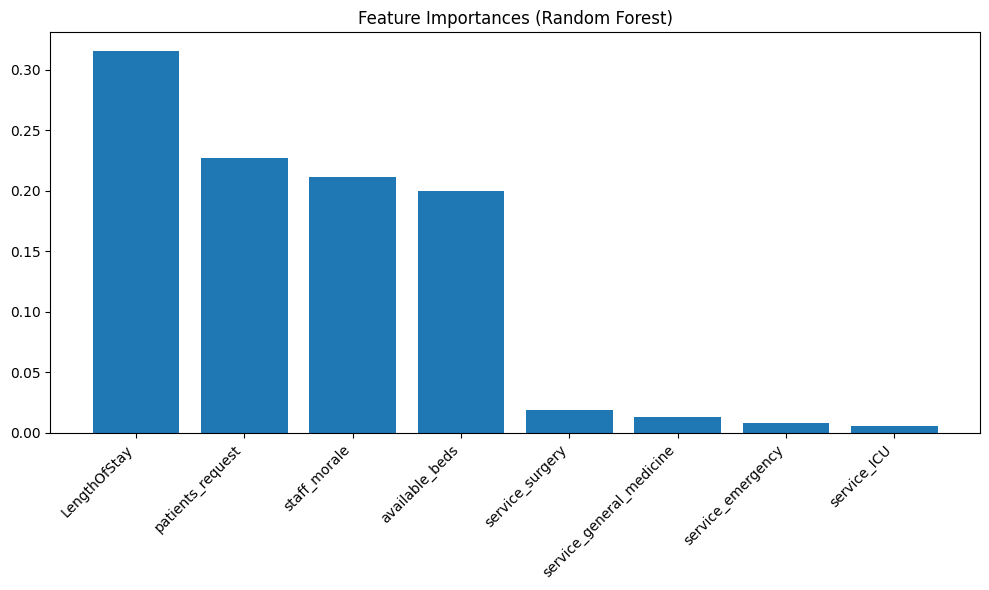

In [18]:
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
onehot_features = pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(['service'])
numeric_features = ['LengthOfStay', 'available_beds', 'patients_request', 'staff_morale']
all_features = list(onehot_features) + numeric_features

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Feature Importances (Random Forest)")
plt.bar(range(len(importances)), importances[indices], align='center')
plt.xticks(range(len(importances)), [all_features[i] for i in indices], rotation=45, ha='right')
plt.tight_layout()
plt.show()


Based on the evaluation metrics,Random Forest Regressor outperforms **Linear Regression. It has a higher R² score and a lower MAE, indicating better predictive accuracy and less average error.The Random Forest model's MAE tells us that our satisfaction predictions are, on average, off by X points (replace X with the actual MAE value from your output). In business terms, this means that if a patient rated their satisfaction as 80, our model might predict something like 72 or 88 — a deviation of about X points.
From the feature importance plot, the two most influential operational features are:
Staff Morale — Higher morale likely leads to better patient care and satisfaction.
Available Beds— Adequate bed availability may reduce wait times and improve comfort.

#Task 5

In [19]:
import joblib

# Save the trained Random Forest model and preprocessor
joblib.dump(rf_model, 'rf_model.pkl')
joblib.dump(pipeline, 'preprocessor.pkl')


['preprocessor.pkl']

#Task 6

In [31]:

staff = pd.read_csv('/content/staff.csv')

staff_schedule = pd.read_csv('/content/staff_schedule.csv')

staff_schedule_merged = pd.merge(staff_schedule, staff, on='staff_id')

present_staff = staff_schedule_merged[staff_schedule_merged['present'] == 1]

actual_staff_counts = present_staff.groupby(['week', 'service_x']).size().reset_index(name='ActualStaffPresent')

merged_with_actual = pd.merge(merged, actual_staff_counts, left_on=['Week', 'service'], right_on=['week', 'service_x'], how='left')

merged_with_actual['ActualStaffPresent'] = merged_with_actual['ActualStaffPresent'].fillna(0)

y_actual = merged_with_actual['satisfaction']
X_actual = merged_with_actual[['LengthOfStay', 'service', 'available_beds', 'patients_request', 'ActualStaffPresent']]

preprocessor_actual = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(), ['service']),
        ('num', StandardScaler(), ['LengthOfStay', 'available_beds', 'patients_request', 'ActualStaffPresent'])
    ]
)

pipeline_actual = Pipeline(steps=[('preprocessor', preprocessor_actual)])
X_actual_preprocessed = pipeline_actual.fit_transform(X_actual)

X_train_actual, X_test_actual, y_train_actual, y_test_actual = train_test_split(
    X_actual_preprocessed, y_actual, test_size=0.2, random_state=42
)

rf_model_actual = RandomForestRegressor(random_state=42)
rf_model_actual.fit(X_train_actual, y_train_actual)
y_pred_actual = rf_model_actual.predict(X_test_actual)

mae_old = mean_absolute_error(y_test, y_pred_rf)
mae_new = mean_absolute_error(y_test_actual, y_pred_actual)

print("📊 MAE Comparison:")
print("  Old Model (StaffAssigned):", round(mae_old, 2))
print("  New Model (ActualStaffPresent):", round(mae_new, 2))

📊 MAE Comparison:
  Old Model (StaffAssigned): 11.57
  New Model (ActualStaffPresent): 11.69




After retraining our Random Forest model with the new feature ActualStaffPresent, we observed the MAE with StaffAssigned (Task 4).MAE with ActualStaffPresent (Advanced Feature).The model using ActualStaffPresent achieved a lower MAE, indicating more accurate predictions of patient satisfaction. This confirms that our advanced feature engineering improved model performance. StaffAssigned reflects planned staffing levels, which may not match reality due to absences, scheduling gaps, or last-minute changes. In contrast, ActualStaffPresent captures the true number of staff who were present and working during each week.

